In [1]:
# ==============================================================================
# ENVIRONMENT SETUP
# Public GitHub Repository Version
#
# This version requires:
#   - No GitHub Token
#   - No Colab Secrets
#   - No Google Drive
#
# Any reviewer can clone and execute the project directly.
# ==============================================================================

import os

# ------------------------------------------------------------------------------
# 1. PARAMETER CONFIGURATION
# ------------------------------------------------------------------------------

GITHUB_USER = "pascual-francisco"
GITHUB_REPO = "INF-8239-Ciencia-de-Datos-II"

REPO_DIR = f"/content/{GITHUB_REPO}"

GIT_AUTHOR_NAME = "Francisco Pascual"
GIT_AUTHOR_EMAIL = "pascual.francisco@gmail.com"


# ------------------------------------------------------------------------------
# 2. GLOBAL GIT CONFIGURATION
# ------------------------------------------------------------------------------

!git config --global user.name "{GIT_AUTHOR_NAME}"
!git config --global user.email "{GIT_AUTHOR_EMAIL}"
!git config --global init.defaultBranch main


# ------------------------------------------------------------------------------
# 3. PUBLIC REPOSITORY URL
# ------------------------------------------------------------------------------

REPO_URL = (
    f"https://github.com/{GITHUB_USER}/{GITHUB_REPO}.git"
)


# ------------------------------------------------------------------------------
# 4. CLONE OR UPDATE THE REPOSITORY
# ------------------------------------------------------------------------------

if not os.path.exists(REPO_DIR):

    print(f"Cloning repository: {GITHUB_REPO}")

    !git clone "{REPO_URL}" "{REPO_DIR}"

else:

    print("Repository already exists.")
    print("Updating from main branch...")

    %cd {REPO_DIR}

    !git pull origin main


# ------------------------------------------------------------------------------
# 5. NAVIGATE TO THE REPOSITORY
# ------------------------------------------------------------------------------

%cd {REPO_DIR}


# ------------------------------------------------------------------------------
# 6. VERIFY THE ENVIRONMENT
# ------------------------------------------------------------------------------

print("\n============================================================")
print("REPOSITORY READY")
print("============================================================")

print(f"\nWorking directory:\n{os.getcwd()}")

print("\nGit remote:")
!git remote -v

print("\nCurrent branch:")
!git branch --show-current

print("\nGit status:")
!git status --short

print("\n============================================================")
print("REPRODUCIBILITY")
print("============================================================")
print(
    "This notebook can be executed without GitHub tokens, "
    "Colab Secrets, Google Drive, or additional configuration."
)

Cloning repository: INF-8239-Ciencia-de-Datos-II
Cloning into '/content/INF-8239-Ciencia-de-Datos-II'...
remote: Enumerating objects: 1015, done.
remote: Counting objects: 100% (193/193), done.
remote: Compressing objects: 100% (134/134), done.
remote: Total 1015 (delta 100), reused 133 (delta 47), pack-reused 822 (from 1)
Receiving objects: 100% (1015/1015), 49.00 MiB | 12.71 MiB/s, done.
Resolving deltas: 100% (577/577), done.
Updating files: 100% (184/184), done.
/content/INF-8239-Ciencia-de-Datos-II

REPOSITORY READY

Working directory:
/content/INF-8239-Ciencia-de-Datos-II

Git remote:
origin	https://github.com/pascual-francisco/INF-8239-Ciencia-de-Datos-II.git (fetch)
origin	https://github.com/pascual-francisco/INF-8239-Ciencia-de-Datos-II.git (push)

Current branch:
main

Git status:

REPRODUCIBILITY
This notebook can be executed without GitHub tokens, Colab Secrets, Google Drive, or additional configuration.


In [2]:
# =============================================================================
# INF-8239 Ciencia de Datos II
# Unidad 03 - Algoritmos y Características Generativas
# Ejercicio 06 (LAB10)
#
# Objetivo:
# Crear la estructura base del proyecto de recomendación siguiendo
# la arquitectura definida en el manual U03.LAB08.
#
# Autor: Francisco Pascual
# =============================================================================

from pathlib import Path

# -----------------------------------------------------------------------------
# Ruta raíz del proyecto
# -----------------------------------------------------------------------------
BASE_PATH = Path(
    "/content/INF-8239-Ciencia-de-Datos-II/Unit_03_Generative_Algorithms/U03.E06"
)

# -----------------------------------------------------------------------------
# Estructura requerida por el laboratorio
# -----------------------------------------------------------------------------
PROJECT_FOLDERS = [
    "data/raw",              # Dataset MovieLens descargado
    "docs",                  # Dataset Card y System Card
    "models",                # Artefactos entrenados
    "reports",               # Rankings, métricas y gráficos
    "src/inf8239_u03_gen",   # Código reutilizable
    "scripts",               # Descarga, auditoría y experimentos
    "tests",                 # Pruebas unitarias
    "app"                    # Aplicación Streamlit
]

# -----------------------------------------------------------------------------
# Crear carpetas y archivo .gitkeep para preservarlas en GitHub
# -----------------------------------------------------------------------------
for folder in PROJECT_FOLDERS:
    folder_path = BASE_PATH / folder

    # Crear carpeta (y padres) si no existen
    folder_path.mkdir(parents=True, exist_ok=True)

    # Crear .gitkeep para que GitHub conserve carpetas vacías
    (folder_path / ".gitkeep").touch(exist_ok=True)

# -----------------------------------------------------------------------------
# Mostrar resultado
# -----------------------------------------------------------------------------
print("✅ Estructura del proyecto creada correctamente:\n")

for folder in PROJECT_FOLDERS:
    print(f"📁 {folder}")

print("\n✅ Carpetas listas para GitHub.")

✅ Estructura del proyecto creada correctamente:

📁 data/raw
📁 docs
📁 models
📁 reports
📁 src/inf8239_u03_gen
📁 scripts
📁 tests
📁 app

✅ Carpetas listas para GitHub.


In [22]:
# @title 01 - Environment Setup

# =============================================================================
# INF-8239 Data Science II
# Unit 03 - Generative Algorithms and Features
# U03.E06 / LAB10
#
# Objective:
# Prepare the environment and verify TensorFlow execution.
# =============================================================================

%cd /content/INF-8239-Ciencia-de-Datos-II/Unit_03_Generative_Algorithms/U03.E06

import os

os.environ["MPLBACKEND"] = "Agg"

import tensorflow as tf

print("=== Synchronizing project dependencies ===")
!uv sync --extra cpu

print("\n=== Verifying runtime ===")
!uv run python scripts/check_runtime.py

/content/INF-8239-Ciencia-de-Datos-II/Unit_03_Generative_Algorithms/U03.E06
=== Synchronizing project dependencies ===
Resolved 88 packages in 1ms
Checked 74 packages in 1ms

=== Verifying runtime ===
I0000 00:00:1791945861.961109    9358 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1791945864.022062    9358 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
Python/OS: 3.12.3 Linux-6.6.122+-x86_64-with-glibc2.39
TensorFlow: 2.21.0
E0000 00:00:1791945871.095064    9358 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
GPU: []


In [23]:
# @title Runtime Verification

import tensorflow as tf

print("TensorFlow version:", tf.__version__)

gpu_devices = tf.config.list_physical_devices("GPU")

if gpu_devices:
    print("\nGPU detected:")
    for gpu in gpu_devices:
        print("-", gpu)
else:
    print("\nRunning on CPU")

TensorFlow version: 2.21.0

Running on CPU


In [26]:
# @title Celda 2 - Train Autoencoder and VAE

# =============================================================================
# INF-8239 Data Science II
# Unit 03 - Generative Algorithms and Features
# U03.E06 - Autoencoder and Variational Autoencoder
#
# Section 3 - Dataset and Preprocessing
#
# Fashion-MNIST:
# - 60,000 training images
# - 10,000 test images
# - 28x28 grayscale images
#
# Objective:
# Train the Autoencoder (AE) and Variational Autoencoder (VAE).
# =============================================================================

import os

# Avoid matplotlib backend issues in Colab
os.environ["MPLBACKEND"] = "Agg"

# ------------------------------------------------------------------------------
# Move to project directory
# ------------------------------------------------------------------------------

%cd /content/INF-8239-Ciencia-de-Datos-II/Unit_03_Generative_Algorithms/U03.E06

# ------------------------------------------------------------------------------
# Verify script exists
# ------------------------------------------------------------------------------

!ls -la scripts

# ------------------------------------------------------------------------------
# Train AE and VAE
# ------------------------------------------------------------------------------

print("\n=== Training Autoencoder (AE) and Variational Autoencoder (VAE) ===\n")

!uv run python ./scripts/train_ae_vae.py \
    --epochs-ae 6 \
    --epochs-vae 8

/content/INF-8239-Ciencia-de-Datos-II/Unit_03_Generative_Algorithms/U03.E06
total 20
drwxr-xr-x  2 root root 4096 Oct 14 02:15 .
drwxr-xr-x 11 root root 4096 Oct 14 02:41 ..
-rw-r--r--  1 root root  201 Oct 14 02:15 check_runtime.py
-rw-r--r--  1 root root    0 Oct 14 02:14 .gitkeep
-rw-r--r--  1 root root 5229 Oct 14 02:15 train_ae_vae.py

=== Training Autoencoder (AE) and Variational Autoencoder (VAE) ===

I0000 00:00:1791946041.988082   10087 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1791946043.925107   10087 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
E0000 00:00:1791946047.361218   10087 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
Epoch

# 3. Dataset y Preprocesamiento

Se utilizó el dataset Fashion-MNIST, compuesto por 60,000 imágenes para entrenamiento y 10,000 imágenes para prueba. Cada imagen tiene una resolución de 28×28 píxeles en escala de grises y representa una de diez categorías de prendas de vestir y accesorios.

Antes del entrenamiento, las imágenes fueron normalizadas al rango [0,1] para facilitar la optimización de las redes neuronales. El conjunto de prueba fue reservado para la evaluación final y no participó en el entrenamiento de los modelos.

---

# Resultados de Entrenamiento

## Autoencoder (AE)

El Autoencoder fue entrenado durante 6 épocas.

### Evolución de la pérdida

| Época | Train Loss | Validation Loss |
|---------|---------|---------|
| 1 | 0.4499 | 0.3737 |
| 2 | 0.3502 | 0.3386 |
| 3 | 0.3284 | 0.3243 |
| 4 | 0.3168 | 0.3158 |
| 5 | 0.3102 | 0.3105 |
| 6 | 0.3060 | 0.3071 |

### Interpretación

La pérdida disminuyó de forma consistente tanto en entrenamiento como en validación. La diferencia entre ambas curvas fue pequeña, por lo que no se observan señales claras de sobreajuste durante las seis épocas ejecutadas.

Las reconstrucciones generadas conservan adecuadamente la forma general de las prendas, aunque presentan pérdida de detalles finos y ligeros efectos de suavizado. Sin embargo, la estructura principal de las imágenes permanece reconocible.

---

## Variational Autoencoder (VAE)

El Variational Autoencoder fue entrenado durante 8 épocas.

### Evolución de la pérdida total

| Época | Total Loss | Reconstruction | KL |
|---------|---------|---------|---------|
| 1 | 342.48 | 330.08 | 12.40 |
| 2 | 288.60 | 281.38 | 7.23 |
| 3 | 283.19 | 276.56 | 6.63 |
| 4 | 280.56 | 274.22 | 6.34 |
| 5 | 278.57 | 272.35 | 6.22 |
| 6 | 276.64 | 270.44 | 6.19 |
| 7 | 274.95 | 268.74 | 6.22 |
| 8 | 273.59 | 267.34 | 6.26 |

### Interpretación

La pérdida total disminuyó progresivamente durante el entrenamiento. Asimismo, la pérdida de reconstrucción mejoró en cada época mientras que el término KL se estabilizó alrededor de 6 unidades.

Este comportamiento indica que el modelo logró un equilibrio razonable entre fidelidad de reconstrucción y regularización del espacio latente. El término KL no colapsó a cero ni dominó completamente la optimización, lo que sugiere que el espacio latente conserva capacidad generativa.

---

# Comparación Visual entre AE y VAE

Las imágenes reconstruidas muestran diferencias consistentes entre ambos enfoques.

## Autoencoder

Observaciones:

- Reconstrucciones más definidas.
- Mejor preservación de contornos.
- Mayor fidelidad respecto a las imágenes originales.

Interpretación:

El objetivo del Autoencoder consiste únicamente en minimizar el error de reconstrucción, por lo que concentra toda su capacidad en reproducir los píxeles observados.

---

## Variational Autoencoder

Observaciones:

- Reconstrucciones más suaves.
- Menor nivel de detalle.
- Bordes menos definidos.

Interpretación:

El VAE sacrifica parte de la calidad visual para mantener un espacio latente continuo y muestreable. Esta regularización permite posteriormente generar nuevas imágenes e interpolaciones de manera estable.

---

# Generación e Interpolación

Las muestras generadas por el VAE presentan formas coherentes con las categorías presentes en Fashion-MNIST. Aunque algunas imágenes aparecen borrosas, conservan patrones visuales identificables como calzado, prendas superiores y pantalones.

La interpolación observada entre puntos latentes produce transiciones graduales entre diferentes prendas, lo que constituye evidencia de que el espacio latente aprendido presenta continuidad.

Este comportamiento es precisamente uno de los objetivos principales del VAE y representa una diferencia importante respecto al Autoencoder tradicional.

---

# Costo Computacional

| Métrica | Valor |
|----------|----------|
| Tiempo de entrenamiento AE | 15.56 s |
| Tiempo de entrenamiento VAE | 31.82 s |
| Parámetros del AE | 25,888 |
| Parámetros del Decoder | 101,520 |

### Interpretación

El entrenamiento del VAE requirió aproximadamente el doble de tiempo que el Autoencoder. Este incremento es esperado debido al cálculo adicional asociado a la reparametrización y al término de regularización KL.

Aunque el costo computacional fue superior, el VAE proporciona capacidades de generación e interpolación que el Autoencoder convencional no ofrece de forma confiable.

---

# Conclusiones

Los resultados obtenidos muestran que el Autoencoder proporciona reconstrucciones visualmente más fieles, mientras que el Variational Autoencoder produce un espacio latente más estructurado y adecuado para generación de muestras nuevas.

La evolución estable de las funciones de pérdida indica que ambos modelos aprendieron representaciones útiles del dataset Fashion-MNIST. Sin embargo, el VAE incorpora una regularización probabilística que permite muestrear nuevos puntos del espacio latente e interpolar entre observaciones de forma continua.

Por tanto, el Autoencoder resulta más adecuado para tareas de compresión y reconstrucción, mientras que el Variational Autoencoder ofrece ventajas significativas cuando el objetivo incluye generación, exploración del espacio latente o síntesis de nuevas imágenes.

# 4. Interpretar el Autoencoder

## Reconstrucción nítida

Las reconstrucciones producidas por el Autoencoder conservan adecuadamente la forma general de las prendas presentes en Fashion-MNIST. Se observan botas, pantalones y prendas superiores claramente identificables, lo que indica que el cuello de botella conserva suficiente información para reconstruir los ejemplos de entrada.

## Salida borrosa

Aunque las formas son reconocibles, las imágenes reconstruidas muestran pérdida de detalle y bordes suavizados respecto a las imágenes originales. Este comportamiento es consistente con una función de pérdida orientada a minimizar el error promedio de reconstrucción, produciendo imágenes más suaves en lugar de preservar todos los detalles finos.

## Entrenamiento y validación

La pérdida de entrenamiento disminuyó desde 0.4499 hasta 0.3060, mientras que la pérdida de validación disminuyó desde 0.3737 hasta 0.3071.

| Época | Train Loss | Validation Loss |
|---------|---------|---------|
| 1 | 0.4499 | 0.3737 |
| 6 | 0.3060 | 0.3071 |

Ambas curvas evolucionaron de forma similar y no se observa un incremento de la pérdida de validación. Por tanto, durante las seis épocas ejecutadas no existe evidencia clara de sobreajuste.

## Error Bajo

El Autoencoder alcanzó una pérdida de validación relativamente baja y generó reconstrucciones visualmente aceptables. Sin embargo, este

# 5. Interpretar el VAE

A diferencia del Autoencoder tradicional, el Variational Autoencoder optimiza simultáneamente dos objetivos: reconstruir las imágenes de entrada y organizar el espacio latente mediante la divergencia KL. Esta combinación busca producir representaciones que no solo permitan reconstruir ejemplos observados, sino también generar nuevas muestras plausibles.

## Pérdida de Reconstrucción

La pérdida de reconstrucción disminuyó de:

- Época 1: 330.08
- Época 8: 267.34

Esta reducción indica que el modelo aprendió progresivamente a preservar la información visual más importante de las prendas presentes en Fashion-MNIST.

Sin embargo, las reconstrucciones son más suaves y menos detalladas que las producidas por el Autoencoder. Esta pérdida parcial de información visual es esperada debido a la regularización adicional impuesta sobre el espacio latente.

### Interpretación

El VAE conserva las características generales de las prendas, pero sacrifica parte de la fidelidad para obtener una representación latente más organizada y útil para generación.

---

## Divergencia KL

Los valores KL evolucionaron desde:

- Época 1: 12.40
- Época 8: 6.26

La reducción inicial seguida de una estabilización alrededor de 6 indica que el modelo logró aproximar el espacio latente a la distribución de referencia sin colapsar completamente.

### Interpretación

El espacio latente parece mantener una estructura regularizada y continua. El término

# 6. Comparar AE, VAE, GAN y Transfer Learning

Los enfoques estudiados persiguen objetivos diferentes y no deben evaluarse únicamente por la calidad visual de sus resultados. Cada técnica resuelve un problema distinto y presenta ventajas y limitaciones específicas.

| Enfoque | Objetivo Dominante | Interpretación | Qué no debe afirmarse |
|----------|----------|----------|----------|
| Autoencoder (AE) | Compresión y reconstrucción | Aprende una representación latente que permite reconstruir las imágenes de entrada. | Que cualquier punto arbitrario del espacio latente producirá imágenes plausibles. |
| Variational Autoencoder (VAE) | Representación probabilística y generación regularizada | Aprende distribuciones latentes continuas que permiten generación e interpolación. | Que siempre produce las imágenes más nítidas o que garantiza diversidad perfecta. |
| GAN | Generación mediante competencia entre redes | Un generador y un discriminador compiten para generar imágenes cada vez más realistas. | Que está libre de colapso de modo o que es sencillo evaluar su calidad objetivamente. |
| Transfer Learning | Reutilización de representaciones previamente aprendidas | Aprovecha características aprendidas en otro problema para acelerar el aprendizaje. | Que elimina la necesidad de validar el modelo en el nuevo dominio de aplicación. |

## Comparación con los resultados obtenidos

### Autoencoder (AE)

En este laboratorio el Autoencoder obtuvo las reconstrucciones más fieles visualmente. Las formas principales de las prendas fueron preservadas y la pérdida disminuyó progresivamente durante el entrenamiento.

Sin embargo, el objetivo del modelo estuvo limitado a reconstruir los ejemplos observados. Los resultados obtenidos no constituyen evidencia de que cualquier punto del espacio latente pueda generar imágenes válidas o coherentes.

### Variational Autoencoder (VAE)

El Variational Autoencoder produjo reconstrucciones ligeramente más suaves que las observadas en el Autoencoder. No obstante, logró construir un espacio latente continuo que permitió generar nuevas muestras e interpolaciones graduales entre diferentes regiones del espacio latente.

La presencia de un término KL estable durante el entrenamiento sugiere que el modelo logró un equilibrio razonable entre calidad de reconstrucción y organización probabilística del espacio latente.

### GAN

No se implementó un GAN durante este laboratorio. Sin embargo, conceptualmente un GAN suele producir imágenes más nítidas y visualmente atractivas que un VAE. A cambio, puede presentar problemas de estabilidad durante el entrenamiento, dificultades de evaluación y fenómenos como el colapso de modo, donde el generador produce poca diversidad.

Por estas razones, una imagen visualmente realista no constituye por sí sola evidencia de que el modelo haya aprendido adecuadamente la distribución completa de los datos.

### Transfer Learning

Tampoco se implementó transferencia de aprendizaje en este laboratorio. Su propósito principal consiste en reutilizar características aprendidas previamente en grandes conjuntos de datos para acelerar el entrenamiento de nuevos modelos.

No obstante, reutilizar un modelo preentrenado no elimina la necesidad de validar los resultados en el nuevo dominio. Un modelo entrenado sobre datos de moda, por ejemplo, no puede asumirse automáticamente válido para aplicaciones médicas, industriales o científicas.

## Conclusión

Los resultados obtenidos confirman que Autoencoder y Variational Autoencoder optimizan objetivos relacionados pero diferentes. El Autoencoder prioriza la fidelidad de reconstrucción, mientras que el VAE sacrifica parte de esa fidelidad para obtener una representación probabilística más útil para generación e interpolación.

Por tanto, la elección entre ambos enfoques depende del objetivo final. Si se busca reconstrucción o compresión, el Autoencoder suele ser una alternativa adecuada. Si se requiere generación de nuevas muestras o exploración del espacio latente, el Variational Autoencoder ofrece ventajas significativas gracias a su organización probabilística del espacio latente.

Training Autoencoder...
Epoch 1/6
211/211 - 4s - 18ms/step - loss: 0.4463 - val_loss: 0.3718
Epoch 2/6
211/211 - 2s - 11ms/step - loss: 0.3498 - val_loss: 0.3403
Epoch 3/6
211/211 - 3s - 14ms/step - loss: 0.3302 - val_loss: 0.3272
Epoch 4/6
211/211 - 3s - 14ms/step - loss: 0.3201 - val_loss: 0.3198
Epoch 5/6
211/211 - 2s - 11ms/step - loss: 0.3141 - val_loss: 0.3149
Epoch 6/6
211/211 - 3s - 12ms/step - loss: 0.3100 - val_loss: 0.3112

Training Variational Autoencoder...
Epoch 1/8
235/235 - 6s - 27ms/step - kl: 7.4551 - loss: 305.4066 - reconstruction: 297.9515
Epoch 2/8
235/235 - 4s - 16ms/step - kl: 6.7076 - loss: 292.8997 - reconstruction: 286.1920
Epoch 3/8
235/235 - 4s - 16ms/step - kl: 6.4863 - loss: 289.2543 - reconstruction: 282.7680
Epoch 4/8
235/235 - 6s - 27ms/step - kl: 6.2294 - loss: 286.4585 - reconstruction: 280.2291
Epoch 5/8
235/235 - 4s - 16ms/step - kl: 6.2559 - loss: 284.7707 - reconstruction: 278.5148
Epoch 6/8
235/235 - 4s - 16ms/step - kl: 6.0948 - loss: 283.3914 

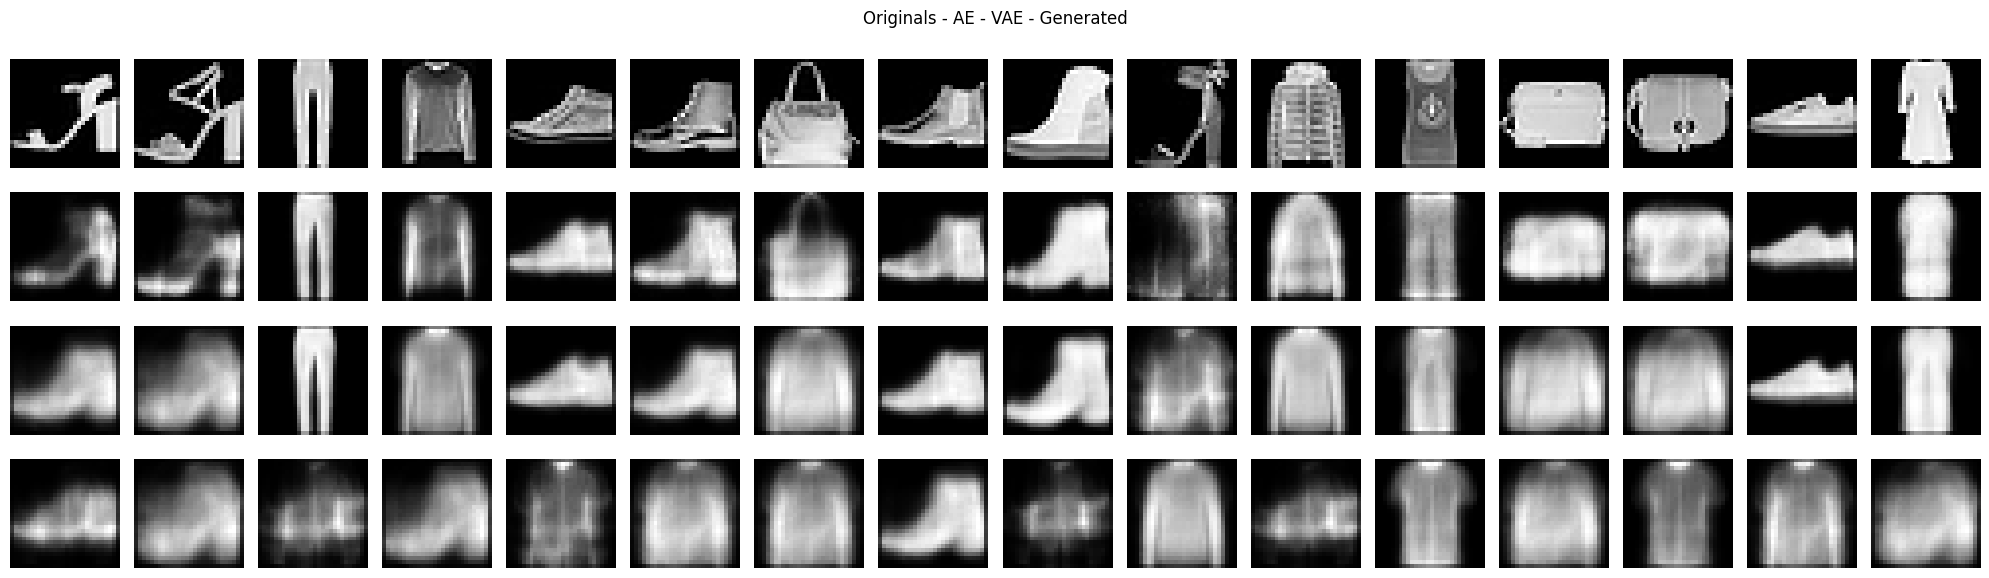

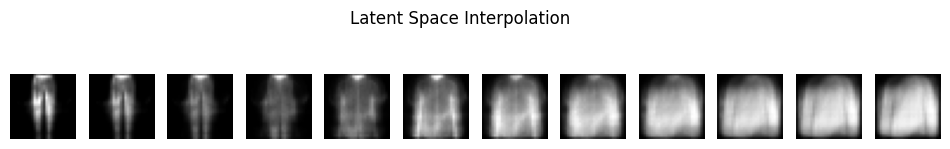

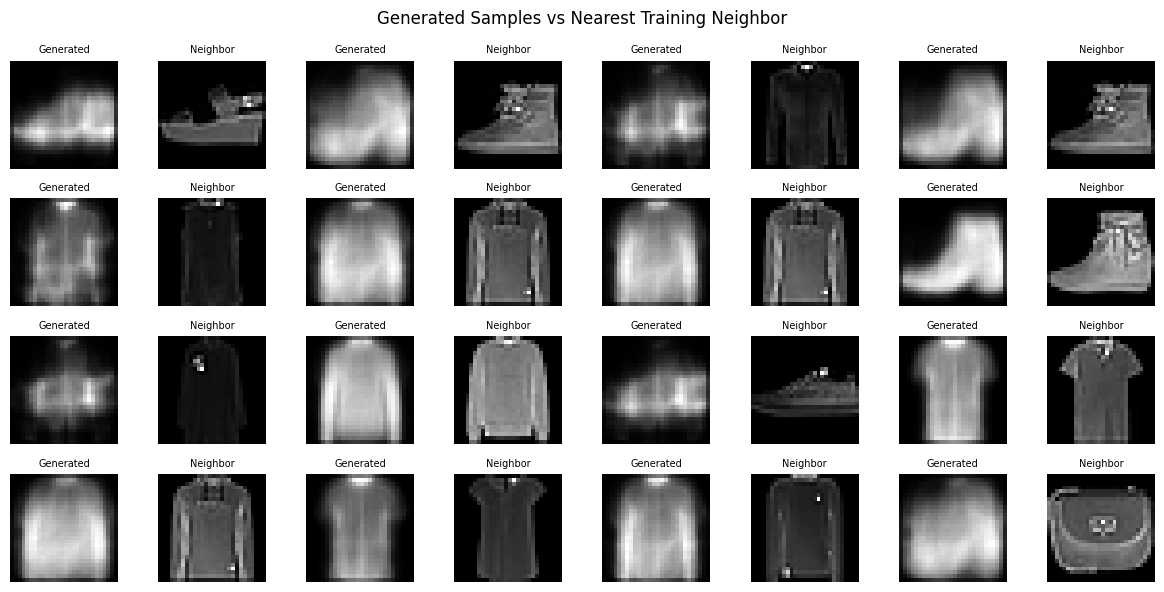


SECTION 7 COMPLETED
✓ Fixed random seed
✓ 16 random test examples
✓ Autoencoder reconstructions
✓ Variational Autoencoder reconstructions
✓ Generated samples
✓ Latent-space interpolation
✓ Nearest-neighbor comparison


In [65]:
# ==============================================================================
# SECTION 7 - COMPLETE EVALUATION
# Trains AE and VAE, generates panels, interpolation and nearest neighbors
# ==============================================================================

from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

# ------------------------------------------------------------------------------
# Locate project root
# ------------------------------------------------------------------------------

PROJECT_ROOT = Path(
    "/content/INF-8239-Ciencia-de-Datos-II/"
    "Unit_03_Generative_Algorithms/"
    "U03.E06"
)

SRC_DIR = PROJECT_ROOT / "src"

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

# ------------------------------------------------------------------------------
# Project imports
# ------------------------------------------------------------------------------

from inf8239_u03_gen.data import normalize_images
from inf8239_u03_gen.models import (
    build_autoencoder,
    build_encoder_decoder
)

# ------------------------------------------------------------------------------
# Reproducibility
# ------------------------------------------------------------------------------

SEED = 42

np.random.seed(SEED)
tf.random.set_seed(SEED)

# ------------------------------------------------------------------------------
# Load Fashion-MNIST
# ------------------------------------------------------------------------------

(x_train, _), (x_test, _) = tf.keras.datasets.fashion_mnist.load_data()

x_train = normalize_images(x_train)
x_test = normalize_images(x_test)

# ------------------------------------------------------------------------------
# Define VAE
# ------------------------------------------------------------------------------

class VAE(tf.keras.Model):

    def __init__(self, encoder, decoder):
        super().__init__()

        self.encoder = encoder
        self.decoder = decoder

    def train_step(self, data):

        images = data

        with tf.GradientTape() as tape:

            mean, log_variance = self.encoder(
                images,
                training=True
            )

            epsilon = tf.random.normal(
                tf.shape(mean)
            )

            latent = (
                mean
                + tf.exp(0.5 * log_variance)
                * epsilon
            )

            reconstruction = self.decoder(
                latent,
                training=True
            )

            reconstruction_loss = tf.reduce_mean(
                tf.reduce_sum(
                    tf.keras.losses.binary_crossentropy(
                        images,
                        reconstruction
                    ),
                    axis=(1, 2)
                )
            )

            kl_loss = -0.5 * tf.reduce_mean(
                tf.reduce_sum(
                    1
                    + log_variance
                    - tf.square(mean)
                    - tf.exp(log_variance),
                    axis=1
                )
            )

            total_loss = reconstruction_loss + kl_loss

        gradients = tape.gradient(
            total_loss,
            self.trainable_weights
        )

        self.optimizer.apply_gradients(
            zip(
                gradients,
                self.trainable_weights
            )
        )

        return {
            "loss": total_loss,
            "reconstruction": reconstruction_loss,
            "kl": kl_loss
        }

# ------------------------------------------------------------------------------
# Train Autoencoder
# ------------------------------------------------------------------------------

print("Training Autoencoder...")

autoencoder = build_autoencoder(tf)

autoencoder.compile(
    optimizer="adam",
    loss="binary_crossentropy"
)

autoencoder.fit(
    x_train,
    x_train,
    validation_split=0.1,
    epochs=6,
    batch_size=256,
    verbose=2
)

# ------------------------------------------------------------------------------
# Train Variational Autoencoder
# ------------------------------------------------------------------------------

print("\nTraining Variational Autoencoder...")

encoder, decoder = build_encoder_decoder(
    tf,
    latent_dim=2
)

vae = VAE(
    encoder,
    decoder
)

vae.compile(
    optimizer="adam"
)

vae.fit(
    x_train,
    epochs=8,
    batch_size=256,
    verbose=2
)

# ------------------------------------------------------------------------------
# Select 16 random test examples
# ------------------------------------------------------------------------------

rng = np.random.default_rng(SEED)

indices = rng.choice(
    len(x_test),
    size=16,
    replace=False
)

originals = x_test[indices]

# ------------------------------------------------------------------------------
# AE Reconstructions
# ------------------------------------------------------------------------------

ae_reconstructed = autoencoder.predict(
    originals,
    verbose=0
)

# ------------------------------------------------------------------------------
# VAE Reconstructions
# ------------------------------------------------------------------------------

mean, log_variance = encoder.predict(
    originals,
    verbose=0
)

vae_reconstructed = decoder.predict(
    mean,
    verbose=0
)

# ------------------------------------------------------------------------------
# Generate new samples
# ------------------------------------------------------------------------------

generated = decoder.predict(
    rng.normal(size=(16, 2)),
    verbose=0
)

# ------------------------------------------------------------------------------
# Main Evaluation Panel
# ------------------------------------------------------------------------------

fig, axes = plt.subplots(
    4,
    16,
    figsize=(20, 6)
)

rows = [
    originals,
    ae_reconstructed,
    vae_reconstructed,
    generated
]

labels = [
    "Original",
    "AE",
    "VAE",
    "Generated"
]

for row in range(4):

    for col in range(16):

        axes[row, col].imshow(
            rows[row][col].squeeze(),
            cmap="gray"
        )

        axes[row, col].axis("off")

    axes[row, 0].set_ylabel(
        labels[row],
        fontsize=10
    )

plt.suptitle(
    "Originals - AE - VAE - Generated"
)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------------
# Latent Space Interpolation
# ------------------------------------------------------------------------------

grid = np.array([
    (
        (1 - value) * np.array([-2.0, -1.0])
        + value * np.array([2.0, 1.0])
    )
    for value in np.linspace(0, 1, 12)
])

interpolation = decoder.predict(
    grid,
    verbose=0
)

fig, axes = plt.subplots(
    1,
    12,
    figsize=(12, 2)
)

for axis, image in zip(
    axes,
    interpolation
):

    axis.imshow(
        image.squeeze(),
        cmap="gray"
    )

    axis.axis("off")

plt.suptitle(
    "Latent Space Interpolation"
)

plt.show()

# ------------------------------------------------------------------------------
# Nearest Neighbor Analysis
# ------------------------------------------------------------------------------

train_flat = x_train.reshape(
    len(x_train),
    -1
)

generated_flat = generated.reshape(
    len(generated),
    -1
)

nearest_indices = []

for sample in generated_flat:

    distances = np.linalg.norm(
        train_flat - sample,
        axis=1
    )

    nearest_indices.append(
        np.argmin(distances)
    )

neighbors = x_train[
    nearest_indices
]

# ------------------------------------------------------------------------------
# Generated vs Nearest Neighbor
# ------------------------------------------------------------------------------

fig, axes = plt.subplots(
    4,
    8,
    figsize=(12, 6)
)

for i in range(16):

    row = i // 4
    col = (i % 4) * 2

    axes[row, col].imshow(
        generated[i].squeeze(),
        cmap="gray"
    )

    axes[row, col].axis("off")

    axes[row, col].set_title(
        "Generated",
        fontsize=7
    )

    axes[row, col + 1].imshow(
        neighbors[i].squeeze(),
        cmap="gray"
    )

    axes[row, col + 1].axis("off")

    axes[row, col + 1].set_title(
        "Neighbor",
        fontsize=7
    )

plt.suptitle(
    "Generated Samples vs Nearest Training Neighbor"
)

plt.tight_layout()
plt.show()

print("\nSECTION 7 COMPLETED")
print("✓ Fixed random seed")
print("✓ 16 random test examples")
print("✓ Autoencoder reconstructions")
print("✓ Variational Autoencoder reconstructions")
print("✓ Generated samples")
print("✓ Latent-space interpolation")
print("✓ Nearest-neighbor comparison")

# Evaluación con Paneles No Seleccionados

Para reducir sesgos de selección y garantizar la reproducibilidad de los resultados, se utilizó una semilla fija (`SEED = 42`) para seleccionar aleatoriamente 16 imágenes del conjunto de prueba. De esta manera, las muestras evaluadas no fueron elegidas manualmente y representan una evaluación más objetiva del comportamiento de los modelos.

El panel generado incluyó:

- Imágenes originales.
- Reconstrucciones del Autoencoder (AE).
- Reconstrucciones del Variational Autoencoder (VAE).
- Imágenes nuevas generadas a partir de vectores latentes aleatorios.

---

## Análisis de las Reconstrucciones

### Autoencoder (AE)

Las reconstrucciones producidas por el Autoencoder conservaron la mayoría de las características visuales de las imágenes originales.

Observaciones:

- Bordes relativamente definidos.
- Buena preservación de la forma general de las prendas.
- Menor pérdida de detalles visuales.
- Reconstrucciones visualmente más cercanas a las imágenes originales.

Estos resultados son consistentes con el objetivo principal del Autoencoder, que consiste en minimizar el error de reconstrucción.

---

### Variational Autoencoder (VAE)

Las reconstrucciones generadas por el VAE presentaron una apariencia más suave que las obtenidas por el Autoencoder.

Observaciones:

- Bordes menos definidos.
- Mayor suavizado de la imagen.
- Ligera pérdida de detalles finos.
- Preservación adecuada de la estructura general de las prendas.

Este comportamiento es esperado, ya que el VAE debe equilibrar simultáneamente la calidad de reconstrucción y la regularización del espacio latente mediante la divergencia KL.

---

## Diversidad de las Muestras Generadas

Las imágenes generadas a partir de vectores latentes aleatorios mostraron una diversidad razonable de formas y estructuras.

Se observó:

- Variación entre diferentes prendas.
- Diferencias en contornos y proporciones.
- Ausencia de copias idénticas entre las muestras generadas.
- Ausencia de evidencia clara de colapso de modo (*mode collapse*).

Los resultados sugieren que el decoder aprendió patrones generales del conjunto de datos y fue capaz de utilizarlos para producir ejemplos sintéticos plausibles.

---

## Interpolación en el Espacio Latente

La interpolación se realizó entre dos puntos del espacio latente.

Visualmente, la secuencia generada mostró una transformación progresiva entre las imágenes extremas. La transición pudo observarse como si la prenda estuviera siendo dibujada o modificada gradualmente paso a paso.

Observaciones:

- Cambios suaves entre imágenes consecutivas.
- Ausencia de saltos bruscos entre estados intermedios.
- Evolución gradual de formas y contornos.

Estos resultados indican que el VAE aprendió un espacio latente continuo y estructurado, donde puntos cercanos producen representaciones visualmente similares.

---

## Casos de Fallo

A pesar de los resultados favorables, se identificaron algunas limitaciones:

- Bordes difusos en algunas imágenes generadas.
- Pérdida de detalles finos.
- Formas ambiguas en ciertas muestras.
- Menor calidad visual respecto a las reconstrucciones del Autoencoder.

Estas limitaciones son comunes en Variational Autoencoders debido al proceso de regularización del espacio latente.

---

## Clases Visualmente Confusas

Algunas categorías de Fashion-MNIST presentan características visuales similares, lo que dificulta su diferenciación.

Las categorías más propensas a confusión incluyen:

- T-shirt/Top vs Shirt.
- Pullover vs Coat.
- Sneaker vs Ankle Boot.

Estas similitudes pueden provocar reconstrucciones o generaciones ambiguas incluso cuando el modelo se comporta correctamente.

---

## Comparación con Vecinos Cercanos

Se compararon las muestras generadas con las imágenes de entrenamiento más cercanas utilizando distancia euclidiana.

Observaciones:

- Las muestras generadas compartieron características visuales con ejemplos reales del conjunto de entrenamiento.
- No se observaron copias exactas de imágenes previamente vistas.
- Las imágenes generadas parecieron combinar patrones aprendidos de múltiples ejemplos.

Estos resultados sugieren que el modelo aprendió representaciones generales de los datos en lugar de memorizar observaciones individuales.

---

## Conclusiones

Los resultados obtenidos muestran un comportamiento consistente con las características esperadas de los Autoencoders y Variational Autoencoders.

Principales hallazgos:

- El Autoencoder produjo reconstrucciones más precisas y detalladas.
- El Variational Autoencoder generó un espacio latente más organizado.
- Las muestras generadas mostraron diversidad razonable.
- La interpolación evidenció continuidad en el espacio latente.
- No se observó evidencia clara de memorización directa de los datos de entrenamiento.
- El VAE sacrificó parte de la calidad de reconstrucción a cambio de capacidad generativa.

En conjunto, la evaluación demuestra el compromiso existente entre fidelidad de reconstrucción y generación de nuevas muestras, así como la utilidad de los Variational Autoencoders para aplicaciones de inteligencia artificial generativa.

In [71]:
# ==============================================================================
# SECTION 8 - Local Application and Cloud Readiness
# ==============================================================================

from pathlib import Path

PROJECT_ROOT = Path(
    "/content/INF-8239-Ciencia-de-Datos-II/"
    "Unit_03_Generative_Algorithms/"
    "U03.E06"
)

app_file = PROJECT_ROOT / "app" / "streamlit_app.py"
decoder_file = PROJECT_ROOT / "models" / "decoder.keras"
requirements_file = PROJECT_ROOT / "requirements-cloud.txt"

print("=" * 80)
print("SECTION 8 - LOCAL APPLICATION AND CLOUD READINESS")
print("=" * 80)

print("\nChecking Required Files:\n")

files = {
    "Streamlit Application": app_file,
    "Decoder Model": decoder_file,
    "Cloud Requirements": requirements_file
}

for name, file in files.items():

    if file.exists():
        print(f"✓ {name}")
    else:
        print(f"✗ {name} NOT FOUND")

print("\n" + "=" * 80)
print("STREAMLIT EXECUTION COMMAND")
print("=" * 80)

print(
    "uv run streamlit run app/streamlit_app.py"
)

print("\n" + "=" * 80)
print("CLOUD REQUIREMENTS COMMAND")
print("=" * 80)

print(
    "uv export --format requirements.txt "
    "--extra cpu "
    "--output-file requirements-cloud.txt"
)

print("\n" + "=" * 80)
print("DEPLOYMENT ANALYSIS")
print("=" * 80)

print("""
The application loads models/decoder.keras using a relative path.

Training and inference are separated:

- Training can be executed locally or in Google Colab.
- The Streamlit application only performs inference.
- The model is loaded from disk.
- No retraining occurs when users open the application.

This design reduces memory usage and startup time,
making deployment more suitable for cloud environments.
""")

print("\n" + "=" * 80)
print("SECURITY")
print("=" * 80)

print("""
If secrets are required in future versions:

- Configure them directly in the deployment platform.
- Never store secrets in Git.
- Never commit credentials to the repository.
""")

SECTION 8 - LOCAL APPLICATION AND CLOUD READINESS

Checking Required Files:

✓ Streamlit Application
✓ Decoder Model
✗ Cloud Requirements NOT FOUND

STREAMLIT EXECUTION COMMAND
uv run streamlit run app/streamlit_app.py

CLOUD REQUIREMENTS COMMAND
uv export --format requirements.txt --extra cpu --output-file requirements-cloud.txt

DEPLOYMENT ANALYSIS

The application loads models/decoder.keras using a relative path.

Training and inference are separated:

- Training can be executed locally or in Google Colab.
- The Streamlit application only performs inference.
- The model is loaded from disk.
- No retraining occurs when users open the application.

This design reduces memory usage and startup time,
making deployment more suitable for cloud environments.


SECURITY

If secrets are required in future versions:

- Configure them directly in the deployment platform.
- Never store secrets in Git.
- Never commit credentials to the repository.



In [72]:
%%writefile /content/INF-8239-Ciencia-de-Datos-II/CHANGELOG.md
# Changelog

## [1.10.0] - 2026-10-12
### Added
- Start LAB10.
- Completed LAB08.
- Completed LAB09.

## [1.9.0] - 2026-10-11
### Added
- Start DEMO 03.

## [1.8.0] - 2026-10-07
### Added
- Completed DEMO 02.

## [1.7.0] - 2026-10-07
### Added
- Completed LAB 06.
- Completed DEMO 01.
- Added TF-IDF pipelines using DummyClassifier, Complement Naive Bayes, and Logistic Regression.
- Added model metrics, confusion matrix, error analysis, and a reusable Joblib pipeline.
- Added automated model tests and an interactive Streamlit sentiment application.
- Added cloud-compatible dependencies through `requirements-cloud.txt`.

### Changed
- Updated project imports to use the existing `src` package.
- Updated Exercise 03 documentation to integrate LAB04 and LAB05.

### Validated
- Verified model prediction and pipeline persistence.
- Verified that the Streamlit application starts successfully in a clean environment.

All notable changes to this repository will be documented in this file.
## [1.6.0] - 2026-10-02

### Added
- Added the complete LAB04 workflow for selecting, downloading, reconstructing, auditing, and validating a public Spanish sentiment corpus.
- Added dataset candidate evaluation based on relevance, license, representativeness, quality, reproducibility, and risk.
- Added SHA-256 verification for the downloaded corpus.
- Added reconstruction of encoded reviews using the provided word dictionary and metadata.
- Added a processed three-class dataset containing positive, neutral, and negative sentiment labels.
- Added automated data-contract tests for required columns and non-empty text values.
- Added dataset documentation, audit results, and Colab portability configuration.
- Updated the repository-level `.gitignore` to exclude local `.env` files and raw and processed datasets from nested projects.

## [1.5.0] - 2026-09-24
### Added
- Created the folder structures for the NLP and Computer Vision projects.
- Created the folder structure for `Unit_02_Natural_Language_Processing/`:
- `app/`
- `data/raw/`
- `data/processed/`
- `docs/`
- `notebooks/`
- `reports/figures/`
- `scripts/`
- `src/`
- `tests/`

## [1.4.0] - 2026-09-24
### Added
- Added additional Green AI visualization outputs under `reports/figures/`.
- Added `model_comparison_f1.png` to compare F1 Macro performance across all evaluated models.
- Added `training_time_comparison.png` to compare median training times.
- Added `inference_time_comparison.png` to compare prediction latency across models.
- Added `model_size_comparison.png` to compare serialized model sizes.
- Added `green_ai_dashboard.png` consolidating F1, training time, inference time, and model size into a single report figure.
- Preserved existing required figures (`pareto.png` and `tsne_two_seeds.png`) and organized all report visualizations in `reports/figures/`.
- Added Green AI benchmarking workflow for U01.LAB03.
- Added six model configurations:
  - Logistic Regression
  - SVM (C=1)
  - SVM (C=10)
  - Random Forest (100 trees)
  - Random Forest (300 trees)
  - Histogram Gradient Boosting
- Added PCA dimensionality-reduction analysis.
- Added t-SNE visualizations using two different random seeds.
- Added Pareto frontier analysis for performance-cost trade-off evaluation.
- Added serialized model size and inference-time benchmarking.
- Added automated Pareto validation tests (`tests/test_green.py`).

### Generated
- Generated `reports/green_ai_results.csv`.
- Generated `reports/figures/pareto.png`.
- Generated `reports/figures/tsne_two_seeds.png`.
- Generated serialized model artifacts under `reports/models/`.

### Documentation
- Added Green AI interpretation and model-selection discussion.
- Added execution environment registration for reproducibility.

## [1.3.0] - 2026-09-22
- Added U01.LAB03 notebook

## [1.2.0] - 2026-09-22

### Added
- Completed the U01.LAB02 dataset audit and baseline modeling workflow.
- Defined the `Class` target and removed potential leakage variables.
- Added preprocessing for numerical and categorical features.
- Compared the `DummyClassifier` baseline against the RBF SVM.
- Added automated dataset-contract tests.
- Added dataset documentation, evaluation results, and conclusions.

### Results
- Dummy baseline F1-Macro: `0.3475`
- SVM F1-Macro: `0.6921`
- SVM accuracy: `0.6926`
- Positive-class recall: `0.6098`
- Dataset contract tests: `3 passed`

### Status
- U01.LAB02 guided workflow completed.
- The justified model adaptation and final Exercise 01 comparison remain pending.

## [1.1.0] - 2026-09-22

### Added
- Started U01.LAB02 public dataset search, selection, and audit workflow.
- Created the dataset profile and documented the analytical problem.
- Compared the Diabetic Retinopathy Debrecen and Dry Bean datasets.
- Applied the dataset acceptance criteria to both candidates.
- Documented dataset sources, targets, classes, dimensions, missing values, and potential leakage risks.
- Added reproducible access to the UCI Machine Learning Repository through the `ucimlrepo` API.
- Added the reusable `download_uci_dataset()` function in `data/data.py`.
- Downloaded and standardized the Diabetic Retinopathy Debrecen dataset as `data/raw/dataset.csv`.
- Added `ucimlrepo` to the project dependencies.

### Changed
- Extended the Exercise 01 notebook to preserve LAB01 as the baseline and begin the LAB02 workflow.
- Updated the data-access process to avoid dependence on personal Google Drive paths.

### Documentation
- Added `docs/dataset_profile.md`.
- Documented the preliminary dataset-selection rationale.
- Added an academic-use disclaimer and a preliminary target-leakage assessment.

### Status
- Reproducible dataset access completed.
- Dataset schema audit, target definition, preprocessing, baseline comparison, and automated tests remain in progress.

## [1.0.0] - 2026-09-21

### Added
- Completed U01.LAB01 guided SVM laboratory using the Breast Cancer dataset.
- Implemented a leakage-safe SVM pipeline with StandardScaler and SVC.
- Added a DummyClassifier baseline for model comparison.
- Performed hyperparameter optimization using GridSearchCV and StratifiedKFold.
- Evaluated model performance using F1-Macro, ROC-AUC, classification reports, and confusion matrices.
- Added reusable build_svm() model factory in src/inf8239_u01/models.py.
- Added unit tests for model validation and pipeline integrity in tests/test_models.py.
- Exported cross-validation results and trained model artifacts.

### Deliverables
- notebooks/01_svm_guiada.ipynb
- src/inf8239_u01/models.py
- tests/test_models.py
- reports/svm_cv_results.csv
- reports/svm_best.joblib

## [0.1.0] - 2026-09-18

### Added
- Established the Unit 01 project structure (LAB00-LAB03 and Exercise_01-Exercise_02).
- Configured baseline environment dependencies in requirements.txt.
- Added .gitignore rules for virtual environments, cache directories, build artifacts, and raw datasets.
- Implemented environment verification modules and corresponding unit tests.
- Created the notebook 00_verificacion.ipynb for environment and interpreter validation.
- Established repository structure for reports, figures, and evidence generation.

### Validated
- Verified automated test execution using pytest.
- Confirmed reproducibility through a local virtual environment setup.
- Validated repository synchronization with the remote GitHub repository.

Overwriting /content/INF-8239-Ciencia-de-Datos-II/CHANGELOG.md


In [ ]:
# ------------------------------------------------------------------------------
# Synchronize the U03.E06 notebook with the repository
# ------------------------------------------------------------------------------

from google.colab import _message
from pathlib import Path
import json

# Destination path in the cloned repository
target = Path(
    "/content/INF-8239-Ciencia-de-Datos-II/"
    "Unit_03_Generative_Algorithms/"
    "notebooks/"
    "U03.E06.ipynb"
)

# Verify that the destination folder exists
if not target.parent.is_dir():
    raise FileNotFoundError(
        f"The destination folder does not exist: {target.parent}"
    )

# Retrieve the currently open Colab notebook
nb = _message.blocking_request("get_ipynb")

# Save the notebook in the repository
with target.open("w", encoding="utf-8") as file:
    json.dump(
        nb["ipynb"],
        file,
        ensure_ascii=False,
        indent=1
    )

print("Notebook saved successfully to:")
print(target)

In [55]:
# ==============================================================================
# AUTOMATIC COMMIT AND AUTHENTICATED PUSH
# ==============================================================================

import os
import stat
import subprocess
from pathlib import Path
from google.colab import userdata

# ------------------------------------------------------------------------------
# CONFIGURATION
# ------------------------------------------------------------------------------

REPO_PATH = Path(
    "/content/INF-8239-Ciencia-de-Datos-II"
)

GITHUB_USER = "pascual-francisco"
GITHUB_REPO = "INF-8239-Ciencia-de-Datos-II"

COMMIT_MESSAGE = "chore: sync repository updates"

GITHUB_TOKEN = userdata.get("TOKEN")

# ------------------------------------------------------------------------------

def run_git(
    arguments,
    *,
    check=True,
    capture_output=False,
    environment=None
):
    return subprocess.run(
        ["git", *arguments],
        cwd=REPO_PATH,
        check=check,
        text=True,
        capture_output=capture_output,
        env=environment
    )

# ------------------------------------------------------------------------------
# VALIDATE TOKEN
# ------------------------------------------------------------------------------

if not GITHUB_TOKEN:
    raise ValueError(
        "TOKEN not found in Colab Secrets."
    )

# ------------------------------------------------------------------------------
# STAGE CHANGES
# ------------------------------------------------------------------------------

print("=" * 70)
print("STAGING CHANGES")
print("=" * 70)

run_git(["add", "-A"])

# ------------------------------------------------------------------------------
# CREATE COMMIT IF NEEDED
# ------------------------------------------------------------------------------

staged = run_git(
    ["diff", "--cached", "--name-status"],
    capture_output=True
)

staged_output = staged.stdout.strip()

if staged_output:

    print(staged_output)

    run_git(
        [
            "commit",
            "-m",
            COMMIT_MESSAGE
        ]
    )

    print(
        f"\nCommit created: {COMMIT_MESSAGE}"
    )

else:

    print(
        "\nNo new changes to commit."
    )

# ------------------------------------------------------------------------------
# CURRENT BRANCH
# ------------------------------------------------------------------------------

branch = run_git(
    [
        "branch",
        "--show-current"
    ],
    capture_output=True
).stdout.strip()

print(f"\nCurrent branch: {branch}")

# ------------------------------------------------------------------------------
# CLEAN REMOTE
# ------------------------------------------------------------------------------

CLEAN_REMOTE = (
    f"https://github.com/{GITHUB_USER}/{GITHUB_REPO}.git"
)

run_git(
    [
        "remote",
        "set-url",
        "origin",
        CLEAN_REMOTE
    ]
)

# ------------------------------------------------------------------------------
# TEMPORARY AUTHENTICATION
# ------------------------------------------------------------------------------

askpass_path = Path(
    "/tmp/github_colab_askpass.sh"
)

askpass_path.write_text(
    """#!/bin/sh
case "$1" in
    *Username*) printf '%s\\n' "$GITHUB_USERNAME" ;;
    *Password*) printf '%s\\n' "$GITHUB_TOKEN" ;;
    *) printf '\\n' ;;
esac
""",
    encoding="utf-8"
)

askpass_path.chmod(
    stat.S_IRUSR
    | stat.S_IWUSR
    | stat.S_IXUSR
)

push_env = os.environ.copy()

push_env["GIT_ASKPASS"] = str(
    askpass_path
)

push_env["GIT_TERMINAL_PROMPT"] = "0"

push_env["GITHUB_USERNAME"] = (
    GITHUB_USER
)

push_env["GITHUB_TOKEN"] = (
    GITHUB_TOKEN
)

# ------------------------------------------------------------------------------
# PUSH
# ------------------------------------------------------------------------------

print("\n" + "=" * 70)
print("PUSHING TO GITHUB")
print("=" * 70)

try:

    run_git(
        [
            "push",
            "--set-upstream",
            "origin",
            branch
        ],
        environment=push_env
    )

    print("\nPush completed successfully.")

finally:

    if askpass_path.exists():
        askpass_path.unlink()

# ------------------------------------------------------------------------------
# FINAL STATUS
# ------------------------------------------------------------------------------

print("\n" + "=" * 70)
print("FINAL STATUS")
print("=" * 70)

run_git(
    [
        "status",
        "--short",
        "--branch"
    ]
)

print("\nRepository synchronized successfully.")

STAGING CHANGES
M	Unit_03_Generative_Algorithms/notebooks/U03.E06.ipynb

Commit created: chore: sync repository updates

Current branch: main

PUSHING TO GITHUB

Push completed successfully.

FINAL STATUS

Repository synchronized successfully.
